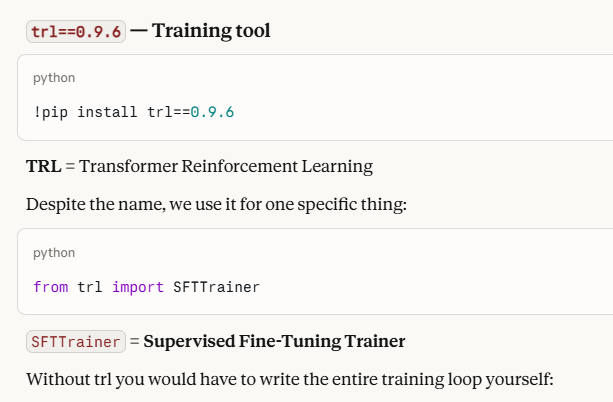

In [1]:
import torch
print(torch.cuda.get_device_name(0))

Tesla T4


In [2]:
import torch
print(torch.cuda.is_available())

True


In [3]:
import gc
import torch
import os

# Free all memory
gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

free = torch.cuda.mem_get_info()[0]/1024**3
print(f"Free VRAM: {free:.2f} GB")

Free VRAM: 14.46 GB


In [4]:
# If model already loaded → delete and reload!

gc.collect()
torch.cuda.empty_cache()

In [5]:
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [6]:
# import torch
# torch.cuda.empty_cache()
# torch.cuda.ipc_collect()

In [7]:
! nvidia-smi

Sun Apr  5 09:49:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P0             27W /   70W |     105MiB /  15360MiB |      1%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [8]:
!pip install bitsandbytes==0.46.1 --quiet
!pip install trl peft accelerate --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 25.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 630.8/630.8 kB 11.3 MB/s eta 0:00:00a 0:00:01


In [9]:
import numpy as np
import torch
import transformers
import trl
import peft

print("numpy:", np.__version__)
print("transformers:", transformers.__version__)
print("trl:", trl.__version__)
print("peft:", peft.__version__)

numpy: 2.0.2
transformers: 5.0.0
trl: 1.0.0
peft: 0.18.1


In [10]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, TrainingArguments, logging, EarlyStoppingCallback
from transformers import PreTrainedModel  
from datasets import load_dataset
from peft import LoraConfig, get_peft_model
from trl import SFTTrainer, SFTConfig
from huggingface_hub import login
import bitsandbytes as bnb
import torch

In [11]:
from kaggle_secrets import UserSecretsClient


user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("hugging_face")  
login(token=hf_token) 

# "it" = Instruction Tuned
# gemma-2-2b-it means below
# "it" means instruction tuned — the model was specially trained to understand and follow human instructions instead of just completing text!



# eskisi  "google/gemma-2-2b-it keyin i changed 
# Gemma-2 was designed for bfloat16 — it resists being converted to float16. T4 doesn't support bfloat16. This is a hardware vs model conflict.




base_model = "google/gemma-7b"  
new_model = "gemma-Doctor_ai"  
dataset_name = "lavita/ChatDoctor-HealthCareMagic-100k" 

# sdpa (Scaled Dot-Product Attention) is built into PyTorch 2.0+ and works on T4
# flash_attention_2 requires Ampere+ (A100/H100), not available on T4
torch_dtype = torch.float16
attn_implementation = "sdpa"

# Configure model quantization settings to reduce memory requirements
bnb_config = BitsAndBytesConfig(
   load_in_4bit=True, 
   bnb_4bit_quant_type="nf4", # Use normalized float 4 quantization for better quality
   bnb_4bit_compute_dtype=torch.float16,  
   bnb_4bit_use_double_quant=True)

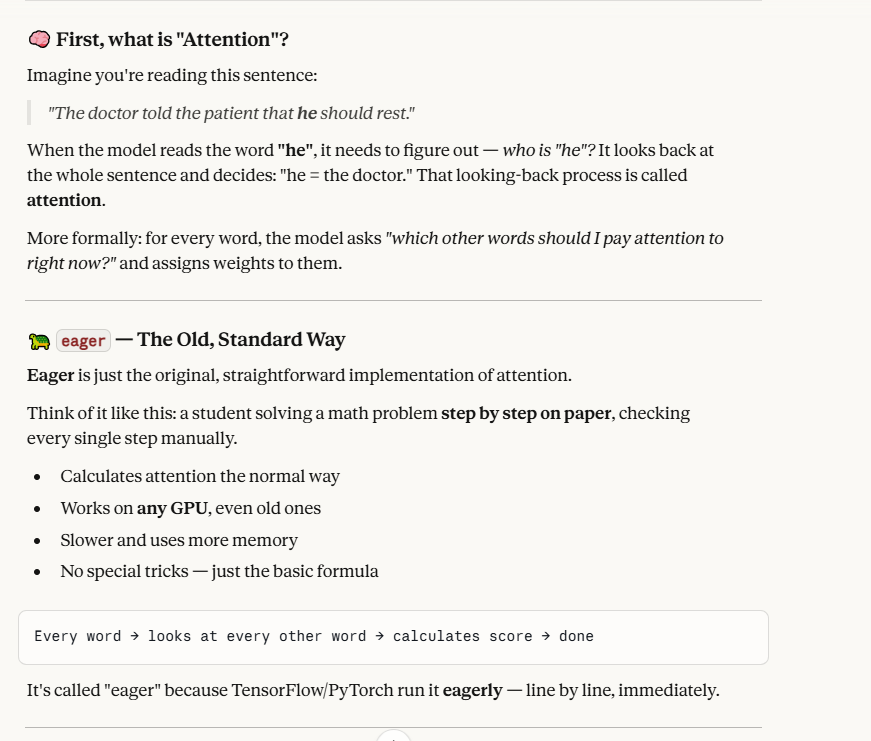

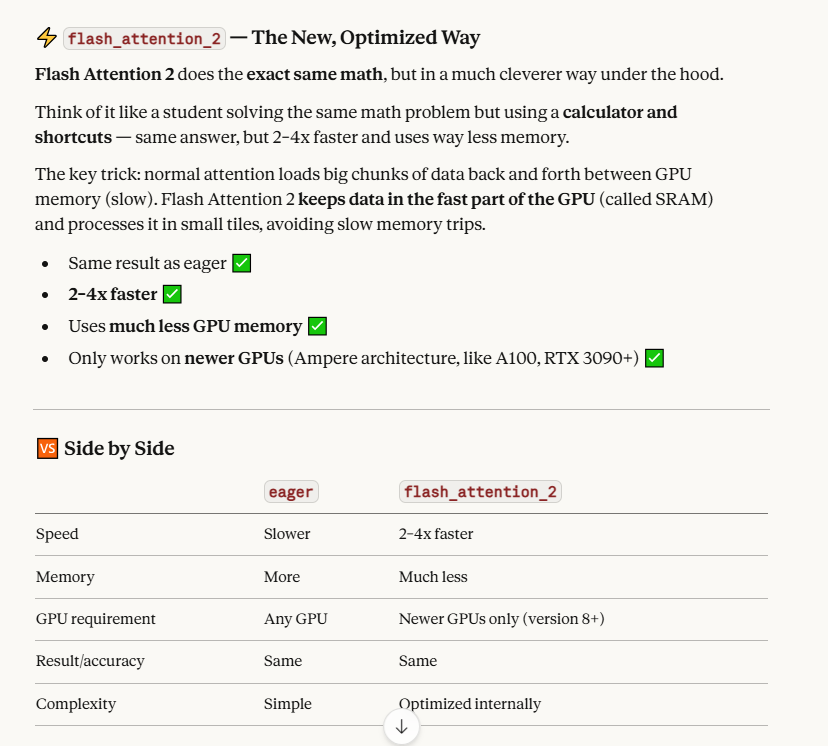

In [12]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [13]:



tokenizer = AutoTokenizer.from_pretrained(
  base_model,                      
  trust_remote_code=True)

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
# Helps fragmentation
# Won’t solve full OOM alone


model = AutoModelForCausalLM.from_pretrained(
  base_model,                          
  quantization_config=bnb_config,      
  device_map="auto",
  torch_dtype=torch_dtype,
  trust_remote_code=True,
  attn_implementation=attn_implementation)

# Why sdpa:

# ✔ Built into PyTorch
# ✔ Faster than "eager"
# ✔ No installation needed
# ✔ Works perfectly on Windows

model.config.pad_token_id = tokenizer.eos_token_id
model.generation_config.pad_token_id = tokenizer.eos_token_id

# This function identifies all linear layers in the model that should be modified with LoRA
def find_all_linear_names(model):
  cls = bnb.nn.Linear4bit               
  lora_module_names = set()              

    
  # Iterate through all named modules in the model
  for name, module in model.named_modules():
      if isinstance(module, cls):       
          names = name.split('.')      
          if len(names) == 1:          
              lora_module_names.add(names[0])
          else:                      
              lora_module_names.add(names[-1])  

  lora_module_names.discard('lm_head')   
  return list(lora_module_names)        


# Get the list of modules that will be fine-tuned using LoRA
modules = find_all_linear_names(model)
print(modules)

print(model.dtype)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 637.4/637.4 kB 11.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 83.6 MB/s eta 0:00:00:00:01
  Attempting uninstall: hf-xet
    Found existing installation: hf-xet 1.3.0
    Uninstalling hf-xet-1.3.0:
      Successfully uninstalled hf-xet-1.3.0
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.4.1
    Uninstalling huggingface_hub-1.4.1:
      Successfully uninstalled huggingface_hub-1.4.1


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/137 [00:00<?, ?B/s]

['down_proj', 'v_proj', 'o_proj', 'up_proj', 'k_proj', 'gate_proj', 'q_proj']
torch.float16


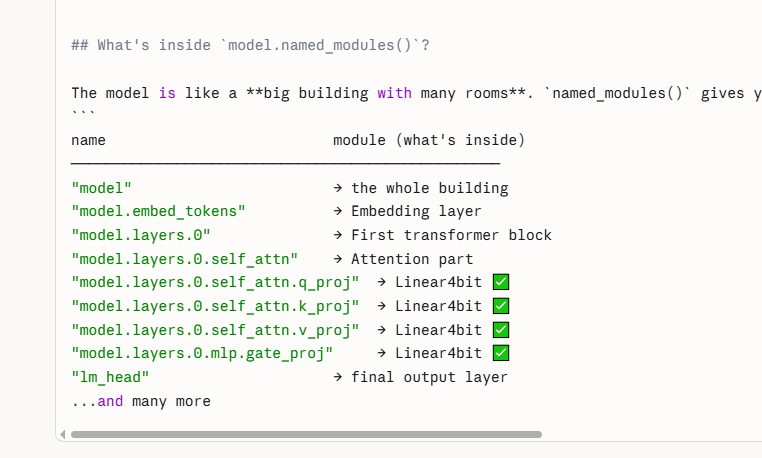

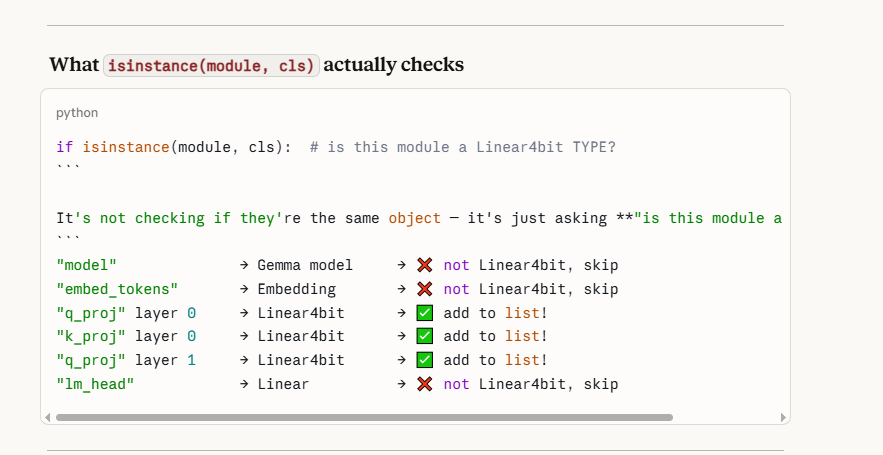

In [14]:
# ![image.png](attachment:ad8d7d7c-0805-4646-baa3-76a9e0c11d50.png)

# r=16             of the adapter (bigger = smarter but slower)
# lora_alpha=32    how strongly the adapter influences the model
# lora_dropout     0.05  randomly turns off 5% of neurons during training to prevent overfitting

# Every layer has two types of learnable values:
# weights → the main learning parameters
# bias → small extra adjustment numbers
# "none" means: don't touch bias values at all, only train LoRA weights.

# lora_alpha = volume knob 🎚️ for the LoRA adapter
# Higher = LoRA speaks louder and influences the final answer more
# Lower = LoRA whispers and original model stays dominant

# Low alpha  → LoRA barely changes the model → learns slowly → safe
# High alpha → LoRA changes model a lot      → learns fast  → risky (can forget original knowledge)

# ______________________________________________________

from peft import LoraConfig, get_peft_model

peft_config = LoraConfig(
   r=32,
   lora_alpha=64,
   lora_dropout=0.05,
   bias="none",
   task_type="CAUSAL_LM",
   target_modules=modules )



import torch

def setup_chat_format(model, tokenizer):
    """
    trl kutubxonasidagi setup_chat_format funksiyasining o'rnini bosuvchi manual funksiya.
    """
    special_tokens = {"additional_special_tokens": ["<|im_start|>", "<|im_end|>"]}
    tokenizer.add_special_tokens(special_tokens)

    model.resize_token_embeddings(len(tokenizer))

    tokenizer.chat_template = "{% for message in messages %}{{'<|im_start|>' + message['role'] + '\n' + message['content'] + '<|im_end|>' + '\n'}}{% endfor %}"

    model.config.chat_template = tokenizer.chat_template

    print("Chat formati muvaffaqiyatli sozlandi!")
    return model, tokenizer


from peft import prepare_model_for_kbit_training


model, tokenizer = setup_chat_format(model, tokenizer)
model = prepare_model_for_kbit_training(model)
model = get_peft_model(model, peft_config)


# Base model (4-bit)
#       ↓
# setup_chat_format → adds tokens to BASE model ✅
#       ↓
# prepare_for_kbit  → prepares BASE model ✅
#       ↓
# get_peft_model    → wraps everything with LoRA ✅



# boshida  shunaqa xato chiqdi keyin bildm lora dan bfloat16 qaytvotganakan, keyin shuni yozdm get_peft_model dan keyin below:
# model = model.to(torch.float16) keyin loradan qaytvotgan bfloat16 float16 boldi va ishladi 


# NotImplementedError: "_amp_foreach_non_finite_check_and_unscale_cuda" not implemented for 'BFloat16'

# The fix from before didn't fully work because the LoRA adapter layers themselves are being created in bfloat16 — 
# the cast needs to happen after get_peft_model().

for name, param in model.named_parameters():
    if param.dtype == torch.bfloat16:
        param.data = param.data.to(torch.float16)


#______________________________________________________
# messages = [
#     {"role": "user",      "content": "I have a cough"},
#     {"role": "assistant", "content": "You may have flu"}
# ]
# 

# The template automatically converts it to:
# 
# <|im_start|>user
# I have a cough<|im_end|>
# <|im_start|>assistant
# You may have flu<|im_end|>


The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Chat formati muvaffaqiyatli sozlandi!


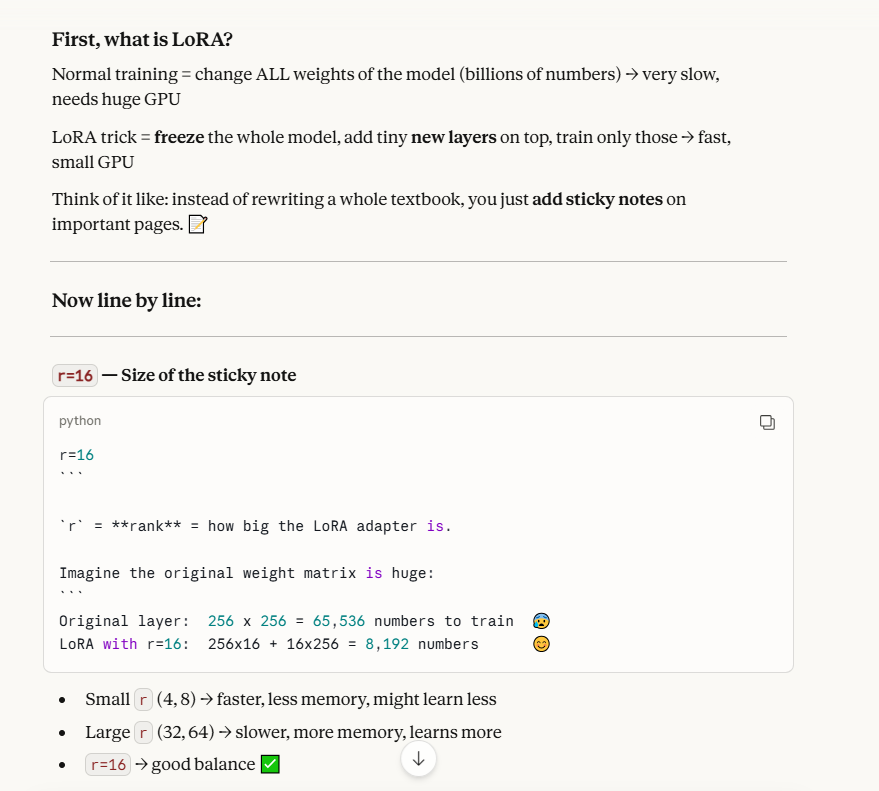

In [15]:

import re
from datasets import load_dataset
from transformers import AutoTokenizer


dataset = load_dataset(
   dataset_name,
   split="all",
   cache_dir="./cache")


dataset = dataset.shuffle(seed=42).select(range(6000))
print(dataset[0])  
print(dataset.column_names)
# ['instruction', 'input', 'output']

def clean_text(text):
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'\b\w+\.\w+\.\w+\S*', '', text)
    text = re.sub(r'\bformatt?(?:ed|ing|s)?\b', '', text, flags=re.IGNORECASE)  # fixed: was \bformat\w+\b which also removed 'formation', 'formative'
    text = re.sub(r'[Cc]hat\s*[Dd]octor\S*', '', text)
    text = re.sub(r'\s*\.\s*\.+', '.', text)                # multiple dots → one dot
    text = re.sub(r'^\.\s*', '', text)                      # dot at beginning → remove
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


def format_chat_template(row):
   cleaned_instruction = clean_text(row["instruction"]) 
   cleaned_input = clean_text(row["input"])             
   cleaned_output = clean_text(row["output"])           

   row_json = [
     {"role": "system", "content": ("You are a medical expert.\n"
                                         "NEVER invent URLs or websites.\n"
                                         "NEVER recommend specific medications.\n"
                                         "ALWAYS recommend proper diagnostic tests first.\n"
                                         "ALWAYS say 'consult a doctor' for serious conditions.")},  
    {"role": "user", "content": f"{cleaned_instruction}\n\n{cleaned_input}"},
    {"role": "assistant", "content": cleaned_output}
]
   row["text"] = tokenizer.apply_chat_template(row_json, tokenize=False)
   return row



dataset = dataset.map(format_chat_template, num_proc=2)
dataset = dataset.train_test_split(test_size=0.1)
# data_collator = lambda batch: tokenizer(batch["text"], return_tensors="pt", padding=True, truncation=True)


#lambda batch: tokenizer(
#     batch["text"],        # take the "text" column from the batch
#     return_tensors="pt",  # convert to PyTorch tensors
#     padding=True,         # pad short sentences
#     truncation=True       # cut long sentences
# )

README.md:   0%|          | 0.00/542 [00:00<?, ?B/s]

data/train-00000-of-00001-5e7cb295b9cff0(…):   0%|          | 0.00/70.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/112165 [00:00<?, ? examples/s]

{'instruction': "If you are a doctor, please answer the medical questions based on the patient's description.", 'input': 'I have been having alot of catching ,pain and discomfort under my right rib.  If I twist to either side especially my right it feels like my rib actually catches on something and at times I have to stop try to catch my breath and wait for it to subside.  There are times if I am laughing too hard that it will do the same thing but normally its more so if I have twisted or moved  a certain way', 'output': 'Hi thanks for asking question. Here you are complaining pain in particular position esp. While turning to a side. So strong possibility is about moderate degree muscular strain. It might have occurred by heavyweight lift or during some activities. Simple analgesic taken. Take rest. Sleep in supine position. Second here Costco Chat Doctor.  Ribs are tender to touch.x-ray also useful. If cough, cold, sore throat present then respiratory infections also has to be ruled

Map (num_proc=2):   0%|          | 0/6000 [00:00<?, ? examples/s]

In [16]:
print(dataset.column_names)

{'train': ['instruction', 'input', 'output', 'text'], 'test': ['instruction', 'input', 'output', 'text']}


In [17]:
print(dataset["train"][0]["text"])

<|im_start|>system
You are a medical expert. 
     NEVER invent URLs or websites. 
     NEVER recommend specific medications. 
     ALWAYS recommend proper diagnostic tests first. 
     ALWAYS say 'consult a doctor' for serious conditions.<|im_end|>
<|im_start|>user
If you are a doctor, please answer the medical questions based on the patient's description.

I have this constant bad taste in my mouth and on my tongue. No matter how many times I brush and floss my teeth it never goes away and causes bad breath. Ive been to my regular doctor and had a complete physical with blood work eveything came back normal, she said it could be acid reflux and put me on a prescription which did nothing she then sent me to an ENT Specialist all tests came back normal she then sent me to a Gastroenterologist in which i had an endoscopy done and that test came back normal as well. The foul taste and odor in my mouth is getting worse. Im at a loss of what to do.<|im_end|>
<|im_start|>assistant
Hello and

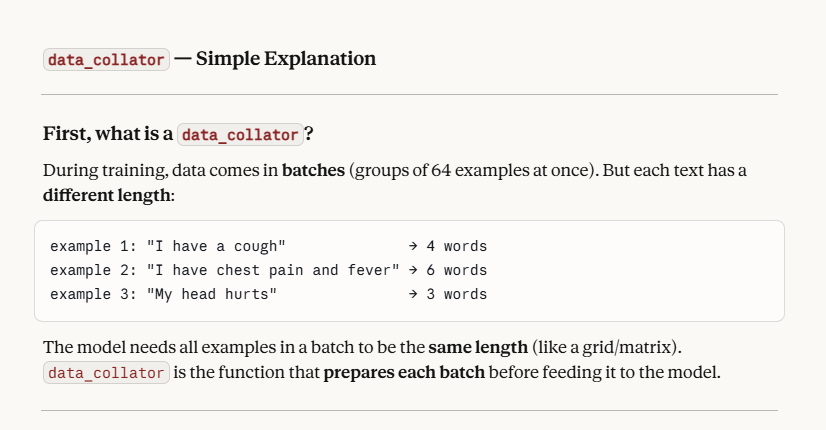

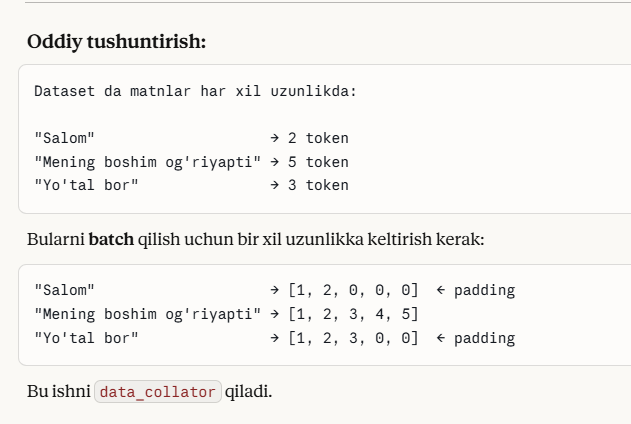

In [ ]:
# gradient_checkpointing=True is set in TrainingArguments below — that controls it
model.config.use_cache = False  # required when gradient_checkpointing=True


training_args = SFTConfig(        # SFTConfig = TrainingArguments + max_seq_length and other SFT-specific args
    output_dir=new_model,
    max_seq_length=1024,             # moved here from SFTTrainer (trl 1.0 requires it in SFTConfig)
    per_device_train_batch_size=1,   # reduced 2→1; logits = batch×seq×vocab, halving batch halves peak VRAM
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=16,  # raised 8→16 to keep effective batch=16 (1×16=2×8)
    optim="paged_adamw_8bit",
    num_train_epochs=3,
    eval_strategy="steps",
    eval_steps=200,
    save_steps=200,
    logging_steps=50,
    warmup_steps=50,              # ~5% of ~1012 total optimizer steps; was 10 (<1%)
    logging_strategy="steps",
    learning_rate=0.0002,
    fp16=True,                    # T4 supports float16 AMP; fp16≠bf16, was off due to bfloat16 confusion
    bf16=False,
    dataloader_drop_last=True,        # helps with CUBLAS on T4
    group_by_length=True,
    load_best_model_at_end=True,
    max_grad_norm=0.3,
    gradient_checkpointing=True,
    report_to=[],
    save_strategy="steps",   
    save_total_limit=3,
    metric_for_best_model="eval_loss",
    greater_is_better=False,       # lower loss = better
    weight_decay=0.01)      # prevents overfitting


#  fp16=True, bf16=False  Only one can be True at a time. fp16 for older GPUs, bf16 for newer.
# group_by_length=True    Groups examples of similar length together in batches:
# report_to=[]            don't report anywhere, keep it local ✅


trainer = SFTTrainer(
    model=model,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    callbacks= [EarlyStoppingCallback(early_stopping_patience = 3 )],    # stop after 3 bad evaluations
    processing_class=tokenizer,
    args=training_args)


Adding EOS to train dataset:   0%|          | 0/5400 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/5400 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/600 [00:00<?, ? examples/s]

In [19]:
# nimaga model = model.to('cuda:0') yozish kere 2 gpu bosa below explanation


#  Simple analogy
# Think of cuda:0 as the manager and other GPUs as workers. 
# The manager must have the full model first, then hands out copies to workers. 
# If the model starts with a worker instead of the manager — nobody knows who's in charge → error.


# Why always cuda:0?
# PyTorch hardcodes cuda:0 as master. You can change it but there's no reason to. Just always use cuda:0.

# Simple 1 line explanation:

# Master = the GPU that owns the real model, splits work, and updates weights. Workers just do calculations and send results back.

# So during training your loss, gradients, weight updates — all happen on cuda:0. Other GPUs are just helping with heavy computation.

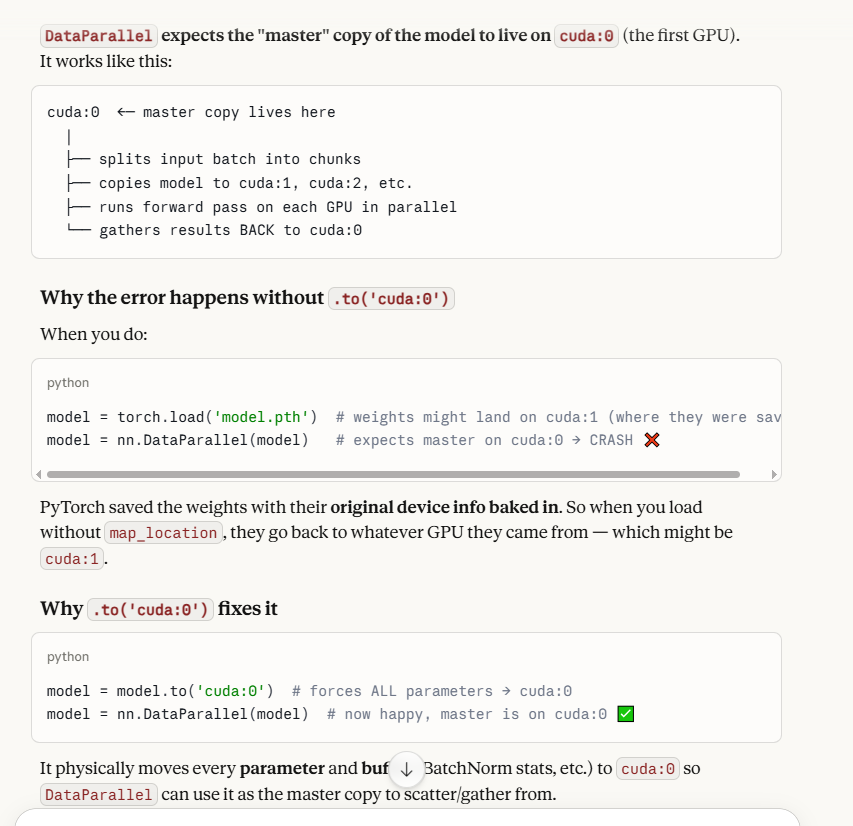

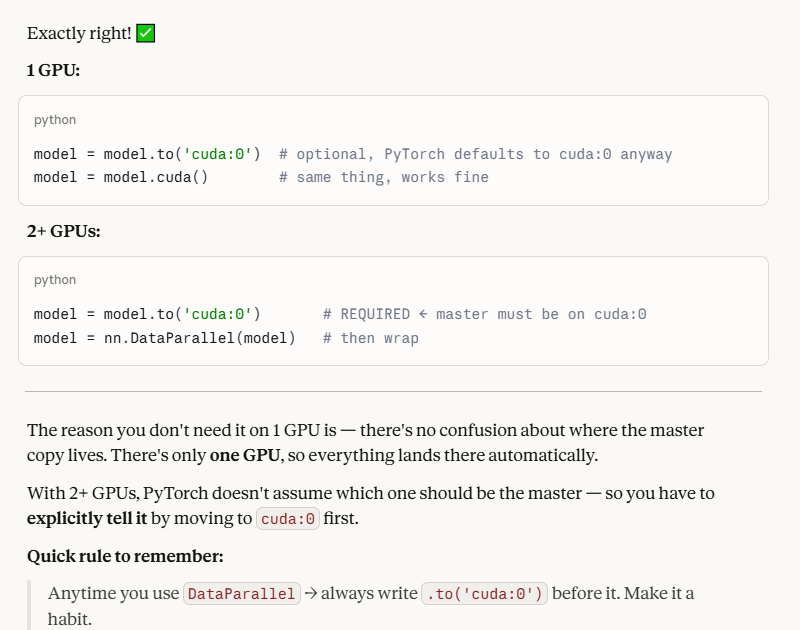

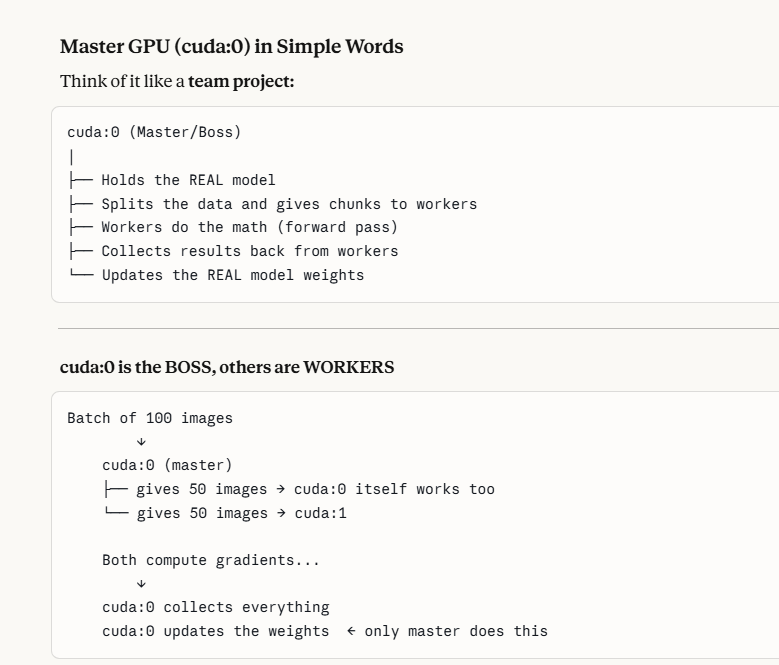

In [20]:
print(torch.cuda.memory_summary())

|===========================================================================|
|                  PyTorch CUDA memory summary, device ID 0                 |
|---------------------------------------------------------------------------|
|            CUDA OOMs: 0            |        cudaMalloc retries: 0         |
|===========================================================================|
|        Metric         | Cur Usage  | Peak Usage | Tot Alloc  | Tot Freed  |
|---------------------------------------------------------------------------|
| Allocated memory      |   3869 MiB |  10044 MiB |  19769 MiB |  15900 MiB |
|       from large pool |   3850 MiB |  10039 MiB |  19686 MiB |  15835 MiB |
|       from small pool |     18 MiB |     33 MiB |     83 MiB |     64 MiB |
|---------------------------------------------------------------------------|
| Active memory         |   3869 MiB |  10044 MiB |  19769 MiB |  15900 MiB |
|       from large pool |   3850 MiB |  10039 MiB |  19686 MiB |

In [ ]:

trainer.train()

# restore cache before saving — was disabled during training for gradient checkpointing
model.config.use_cache = True

model.save_pretrained("/kaggle/working/final_model")      
tokenizer.save_pretrained("/kaggle/working/final_model")  
merged_model = model.merge_and_unload()                
merged_model.save_pretrained("/kaggle/working/merged_model") 
merged_model.push_to_hub(new_model)                     
tokenizer.push_to_hub(new_model)                         

print("SAVED ")

# data collator nimaga ishlatmadm  explanation below 

Step,Training Loss,Validation Loss


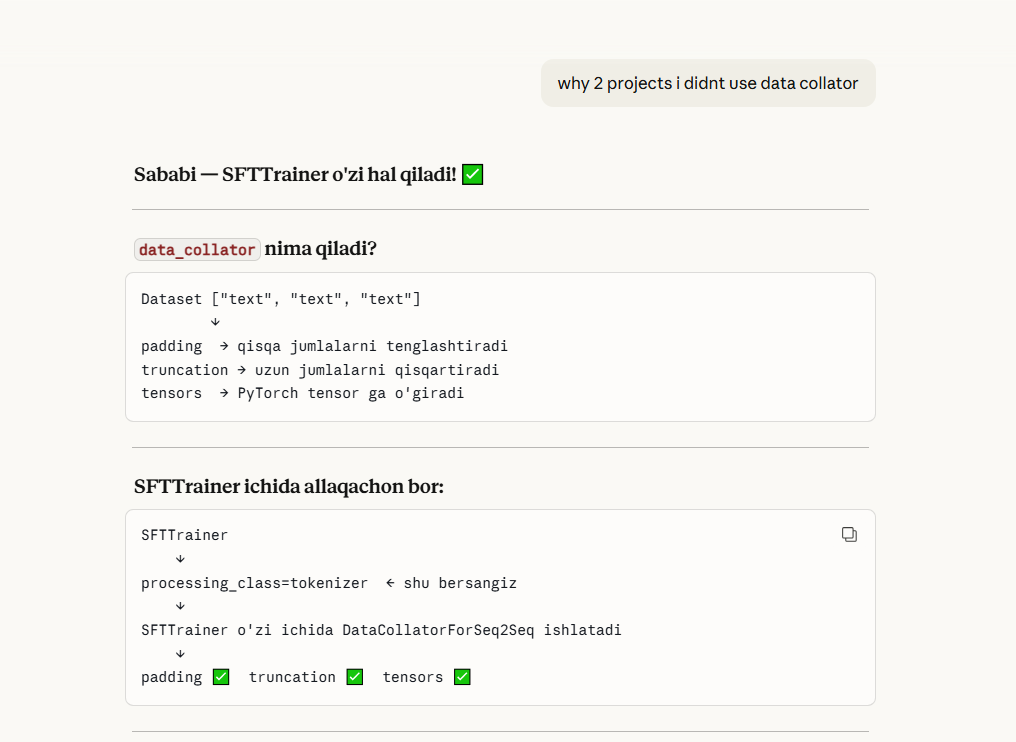

In [ ]:
# We add first, then remove. Let me show exactly what happens:
# Gemma weights: [0.5, 0.3, 0.8]
#     +
# LoRA adapter:  [0.2, 0.2, 0.2]
#     =
# merged:        [0.7, 0.5, 1.0]  ← LoRA knowledge baked in 

# LoRA layers:   removed from memory 
#___________________________________________


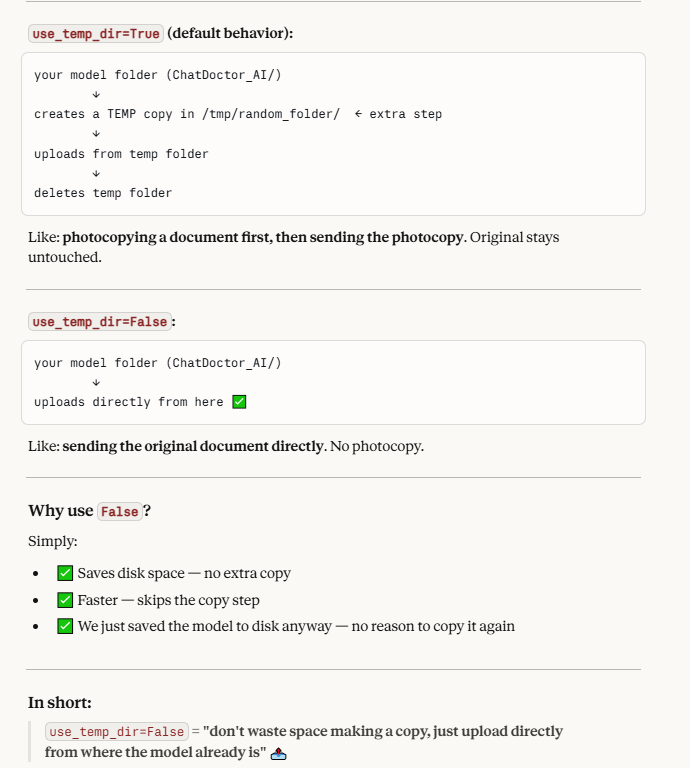

In [ ]:
# 1 chi marta test qivommiz 

tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.pad_token_id

from transformers import GenerationConfig

messages = [
    {"role": "system", "content": '''You are a medical expert.
        NEVER invent URLs or websites.
        NEVER recommend specific medications.
        ALWAYS recommend proper diagnostic tests first.
        ALWAYS say 'consult a doctor' for serious conditions.'''},
    {"role": "user", "content": "I have a persistent cough, night sweats, and recent weight loss. I’ve been to multiple doctors with no diagnosis yet. Could these symptoms be related to tuberculosis or another serious illness? Please provide a detailed answer considering possible causes and recommended next steps. Write down medicines that can cure my illness"}
]

prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs = tokenizer(prompt, return_tensors='pt', padding=True, truncation=True).to("cuda")

#__________________________________________________________________

# apply_chat_template function shunaqa structure qiberadi below 
#    row_json = [
#     {"role": "user", "content": f"{cleaned_instruction}\n\n{cleaned_input}"},
#     {"role": "assistant", "content": cleaned_output}
# ]
#    row["text"] = tokenizer.apply_chat_template(row_json, tokenize=False)


# add_generation_prompt = True → adds <|im_start|>assistant at the end, telling the model "now it's your turn to speak"

#________________________________________________________________


outputs = model.generate(
    **inputs,
    do_sample=True,
    max_new_tokens=512,
    top_k=50,                   # only consider top 50 words at each step
    top_p=0.85,                 # only consider words covering 85% probability
    temperature=0.3,            # how creative/random the answer is
    no_repeat_ngram_size=3,     # never repeat same 3 words
)

response = tokenizer.decode(outputs[0], skip_special_tokens=True).split("assistant")[-1].strip()
print(response)

#____________________________________________________________________

# temperature=0.0  →  [99%, 1%, 0%, 0%]   → always same word, robotic 🤖
# temperature=0.3  →  [85%, 12%, 2%, 1%]  → focused, factual ✅ (our case)
# temperature=1.0  →  [40%, 30%, 20%, 10%] → balanced, natural
# temperature=1.5  →  [25%, 22%, 20%, 18%] → creative, risky 🎨
# temperature=2.0  →  [26%, 25%, 25%, 24%] → almost random, nonsense 😵

In [ ]:
# 2 chi marta test qivommiz 

tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.pad_token_id

from transformers import GenerationConfig

messages = [
     {"role": "system", "content": '''You are a medical expert.
        NEVER invent URLs or websites.
        NEVER recommend specific medications.
        ALWAYS recommend proper diagnostic tests first.
        ALWAYS say 'consult a doctor' for serious conditions.'''},
    {"role": "user", "content": "I have a persistent cough, night sweats, and recent weight loss. I’ve been to multiple doctors with no diagnosis yet. Could these symptoms be related to tuberculosis or another serious illness? Please provide a detailed answer considering possible causes and recommended next steps."}
]

prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
inputs = tokenizer(prompt, return_tensors='pt', padding=True, truncation=True).to("cuda")

outputs = model.generate(
    **inputs,
    do_sample=True,
    max_new_tokens=512,
    top_k=50,
    top_p=0.85,  
    temperature=0.3,  
    no_repeat_ngram_size=3)

response = tokenizer.decode(outputs[0], skip_special_tokens=True).split("assistant")[-1].strip()
print(response)


In [ ]:
# # LOAD THE MODEL 

# from transformers import AutoModelForCausalLM, AutoTokenizer
# import torch

# model_name = "Xasan01/tiny-Llama-ChatDoctor"

# tokenizer = AutoTokenizer.from_pretrained(model_name)

# model = AutoModelForCausalLM.from_pretrained(
#     model_name,
#     torch_dtype=torch.bfloat16,
#     device_map="auto")

In [ ]:
# # TO CHECK AFTER UPLOADED MY MODEL FROM HUGGING FACE 

# import gradio as gr

# def chat(message, history):
#     tokenizer.pad_token = tokenizer.eos_token
#     messages = [
#         {"role": "system", "content": "You are an expert trading assistant specializing in US stock market analysis, technical analysis, and fundamental analysis."},
#         {"role": "user", "content": message}
#     ]
#     prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
#     inputs = tokenizer(prompt, return_tensors="pt").to("cuda")
#     outputs = model.generate(
#         **inputs,
#         max_length=700,
#         do_sample=True,
#         temperature=0.2,
#         top_p=0.9,
#         top_k=50,
#         repetition_penalty=1.2,
#         no_repeat_ngram_size=3,
#     )
#     response = tokenizer.decode(outputs[0], skip_special_tokens=True).split("assistant")[-1].strip()
#     response = response.split("[/INST]")[-1].strip()
#     return response

# gr.ChatInterface(
#     fn=chat,
#     title="📈 Trading Assistant",
#     description="Ask me anything about stocks, technical analysis, RSI, MACD, and more.",
#     examples=[
#         "What is RSI and how do I use it?",
#         "Explain MACD with an example",
#         "What is the difference between support and resistance?",
#         "How does dollar-cost averaging work?",
#     ],
#     theme=gr.themes.Soft()).launch(share=True)